# NYSE Closing Auction Imbalance — Homework Notebook

This notebook is self-contained. Every helper you need is defined inside the notebook. Fill-in code cells are marked `# TODO`.

---

## Background

### The Designated Market Maker (DMM)

Each NYSE-listed stock has one Designated Market Maker — the modern descendant of the floor specialist. The DMM has two obligations that matter for this assignment:

1. **Run the opening and closing auctions.** The DMM is the only participant permitted to execute parity-interest against certain orders at the cross. They use "d-Quote" interest and the exchange's e-Quote tools to facilitate a fair print.
2. **Provide continuous two-sided quotes** during regular trading hours, with maximum-spread obligations tied to the name's price band.

At 15:50 ET the closing auction opens and the DMM begins publishing **MsgType 105 Imbalance messages** to the tape — every time any field changes, typically once per second. These messages let *anyone* on the tape see the imbalance in the DMM's on-close book and decide whether to step in and trade against it.

### On-Close (OC) order types

Orders in the closing auction are separate from the continuous book:

* **MOC (Market-on-Close)** — a market order that executes only at the closing cross price.
* **LOC (Limit-on-Close)** — a limit order that executes at the closing cross price *only if* the cross clears at or better than the limit.
* **Closing Offset orders** — limit orders that can only be used to offset a published imbalance (they join the liquidity side short of interest).

### Timing rules (NYSE Tape A)

| time | event |
|---|---|
| **15:50:00** | Closing auction opens. First MsgType 105 is published. MOC and LOC orders may no longer be *entered* or *cancelled*. |
| 15:50 → 15:58 | MsgType 105 disseminated continuously. Closing Offset orders may be entered to reduce the published imbalance. Reserve Orders' hidden quantity joins the match volume. |
| **15:58:00** | "Imbalance freeze." MOC, LOC, and Closing Offset orders may no longer be modified. |
| 15:58 → 16:00 | MsgType 105 keeps disseminating but no user can change OC interest. Only market-maker D-quote interest adjusts. |
| **16:00:00** | Closing cross executes; a single MsgType 111 print with `cross_type = '6'` is sent. This is the official close. |

**Implication for this assignment.** The 15:50 snapshot is the first observable state of the on-close book. It represents all MOC, LOC, and Closing Offset interest that has already been committed and can no longer be cancelled.

---

## Data

Five NYSE Tape A Integrated Binary Feed partition files covering **2026-01-02**:

```
EQY_US_NYSE_IBF_{1..5}_20260102.gz
```

The five files are also uploaded to S3 at **`s3://ioer4733-data/NYSE_IBF/`** (bucket `ioer4733-data`, prefix `NYSE_IBF`). If they aren't already in your working directory, run the optional download cell below — it uses the `s3_utils.py` helper (copy it plus `s3_credentials.json` from `Notes/Week_12/`). Together the five files cover ~1,600 NYSE-listed symbols. You will distill them into an HDF5 file keeping only the fields needed for this assignment, then build two strategies and compute their PLs.

MsgType 105 field layout (spec §10, 24 fields):
```
msg_type, seq_num, source_time, symbol, symbol_seq_num,
reference_price, paired_qty, total_imbalance_qty, market_imbalance_qty,
auction_time, auction_type, imbalance_side, cont_book_clearing_price,
auction_interest_clearing_price, ssr_filing_price, indicative_match_price,
upper_collar, lower_collar, auction_status, freeze_status, num_extensions,
unpaired_qty, unpaired_side, significant_imbalance
```

`auction_type = 'C'` is the closing auction; `imbalance_side` is `'B'` / `'S'` / space.

In [1]:
import gzip
import re
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

HERE        = Path.cwd()
CACHE       = HERE / 'ibf_cache.h5'
TARGET_DATE = '20260102'
NEXT_DATE   = '20260105'
DOLLAR_IMBALANCE_THRESHOLD = 500_000
DOLLAR_PER_NAME            = 100_000

---
## Optional: download the five IBF files from S3

Skip this cell if the files are already in the current directory. Otherwise,
copy `s3_utils.py` and `s3_credentials.json` from `Notes/Week_12/` into this
directory and run the cell below. The files live in the S3 bucket
`ioer4733-data` under prefix `NYSE_IBF`, so `read_binary_from_s3(fname)`
returns the raw bytes.

In [2]:
# Optional - only needed if the five .gz files are not already in HERE.
missing = [f'EQY_US_NYSE_IBF_{p}_{TARGET_DATE}.gz' for p in range(1, 6)
           if not (HERE / f'EQY_US_NYSE_IBF_{p}_{TARGET_DATE}.gz').exists()]

if missing:
    from s3_utils import read_binary_from_s3
    for fname in missing:
        (HERE / fname).write_bytes(read_binary_from_s3(fname))
    print(f'downloaded {len(missing)} files from s3://ioer4733-data/NYSE_IBF/')
else:
    print('all 5 files already present; skipping download')

all 5 files already present; skipping download


---
## Helper definitions (just run — no edits)

These cells define the parser, the cache builder, and the cache loader.

In [3]:
IBF_COLS = [
    'msg_type', 'seq_num', 'source_time',
    'symbol', 'symbol_seq_num',
    'reference_price', 'paired_qty', 'total_imbalance_qty',
    'market_imbalance_qty', 'auction_time', 'auction_type',
    'imbalance_side', 'cont_book_clearing_price',
    'auction_interest_clearing_price', 'ssr_filing_price',
    'indicative_match_price', 'upper_collar', 'lower_collar',
    'auction_status', 'freeze_status', 'num_extensions',
    'unpaired_qty', 'unpaired_side', 'significant_imbalance',
]

IBF_FNAME_RE       = re.compile(r'EQY_US_NYSE_IBF_(\d+)_(\d{8})\.gz$')
CROSS_TYPE_CLOSING = '6'


def parse_single_gz(path):
    imb_rows, closes, day_vol = [], {}, defaultdict(int)
    with gzip.open(path, 'rt', newline='') as f:
        for line in f:
            if line.startswith('105,'):
                imb_rows.append(line.rstrip('\n').split(','))
            elif line.startswith('111,'):
                row = line.rstrip('\n').split(',')
                try:
                    v = int(row[7]); day_vol[row[3]] += v
                    if len(row) > 8 and row[8] == CROSS_TYPE_CLOSING:
                        closes[row[3]] = (float(row[6]), v, row[2])
                except (ValueError, IndexError):
                    pass
            elif line.startswith(('103,', '104,')):
                row = line.rstrip('\n').split(',')
                try: day_vol[row[3]] += int(row[8])
                except (ValueError, IndexError): pass
            elif line.startswith('110,'):
                row = line.rstrip('\n').split(',')
                try: day_vol[row[3]] += int(row[7])
                except (ValueError, IndexError): pass
    return imb_rows, closes, day_vol

In [4]:
def build_ibf_cache(gz_paths, hdf5_path):
    all_imb, all_daily = [], []
    for p in gz_paths:
        m = IBF_FNAME_RE.search(p.name)
        part, date = int(m.group(1)), m.group(2)
        imb_rows, closes, day_vol = parse_single_gz(p)

        imb = pd.DataFrame(imb_rows, columns=IBF_COLS)
        imb.insert(0, 'partition', part); imb.insert(0, 'date', date)

        daily = (pd.DataFrame(
                    [(s, px, v, t) for s, (px, v, t) in closes.items()],
                    columns=['symbol', 'close_px', 'close_vol', 'close_time'])
                 .merge(pd.DataFrame(list(day_vol.items()),
                                     columns=['symbol', 'total_vol']),
                        on='symbol', how='outer'))
        daily.insert(0, 'partition', part); daily.insert(0, 'date', date)

        all_imb.append(imb); all_daily.append(daily)
        print(f'  parsed {p.name}: {len(imb):>7,d} 105s, {len(daily):>5,d} symbols')

    imb_df   = pd.concat(all_imb,   ignore_index=True)
    daily_df = pd.concat(all_daily, ignore_index=True)

    for c in ('reference_price', 'paired_qty', 'total_imbalance_qty',
              'market_imbalance_qty', 'cont_book_clearing_price',
              'indicative_match_price', 'unpaired_qty'):
        imb_df[c] = pd.to_numeric(imb_df[c], errors='coerce')
    imb_df['imbalance_side'] = imb_df['imbalance_side'].astype(str).str.strip()
    imb_df['auction_type']   = imb_df['auction_type'].astype(str).str.strip()
    side_sign = imb_df['imbalance_side'].map({'B': 1, 'S': -1}).fillna(0)
    imb_df['signed_qty']       = side_sign * imb_df['total_imbalance_qty']
    imb_df['dollar_imbalance'] = imb_df['signed_qty'] * imb_df['reference_price']

    with pd.HDFStore(hdf5_path, mode='w', complevel=5, complib='zlib') as s:
        s.put('imb',   imb_df,   format='table',
              data_columns=['date', 'symbol', 'auction_type'])
        s.put('daily', daily_df, format='table',
              data_columns=['date', 'symbol'])
    print(f'\nWrote {hdf5_path} ({hdf5_path.stat().st_size/1e6:.1f} MB): '
          f'{len(imb_df):,} 105s, {len(daily_df):,} (date, symbol) rows')
    return imb_df, daily_df


def load_cache(hdf5_path, date=None):
    with pd.HDFStore(hdf5_path, mode='r') as s:
        where = f"date == '{date}'" if date else None
        imb   = s.select('imb',   where=where)
        daily = s.select('daily', where=where)
    daily = (daily.groupby(['date', 'symbol'], as_index=False)
                  .agg(close_px=('close_px', 'first'),
                       close_vol=('close_vol', 'first'),
                       close_time=('close_time', 'first'),
                       total_vol=('total_vol', 'sum')))
    return imb, daily

---
## Question 1 — Build the HDF5 cache

### 1a. Find the 5 gz files

Assign `gz_files` to a sorted list of every path in the current working directory whose filename matches `EQY_US_NYSE_IBF_*_20260102.gz`. Hint: `HERE.glob(...)` returns a generator of `pathlib.Path` objects; wrap it in `sorted(...)`.

In [5]:
# TODO: Assign to `gz_files` a Python list of 5 pathlib.Path objects, one per
#       gz file in the current directory HERE. Use:
#         HERE.glob('EQY_US_NYSE_IBF_*_20260102.gz')   # returns a generator
#       and wrap the result in sorted(...) to get a list with stable order.
gz_files: list = sorted(HERE.glob('EQY_US_NYSE_IBF_*_20260102.gz'))

for p in gz_files:
    print(p.name)
print(f'\nTotal: {len(gz_files)} files')


EQY_US_NYSE_IBF_1_20260102.gz
EQY_US_NYSE_IBF_2_20260102.gz
EQY_US_NYSE_IBF_3_20260102.gz
EQY_US_NYSE_IBF_4_20260102.gz
EQY_US_NYSE_IBF_5_20260102.gz

Total: 5 files


### 1b. Build the cache

Call `build_ibf_cache(gz_files, CACHE)`; assign the two returned DataFrames to `imb_df, daily_df`. Expect ~60–120 seconds.

In [6]:
# TODO: Call build_ibf_cache(gz_files, CACHE). It returns a tuple of
#       (pd.DataFrame, pd.DataFrame) - the raw imbalance table and the daily
#       close+volume table - and writes them to the HDF5 file at CACHE.
#       You don't need these two DataFrames below (Q1c re-loads from the cache).
imb_df, daily_df = build_ibf_cache(gz_files, CACHE)


  parsed EQY_US_NYSE_IBF_1_20260102.gz:  58,369 105s,   314 symbols
  parsed EQY_US_NYSE_IBF_2_20260102.gz:  54,928 105s,   314 symbols
  parsed EQY_US_NYSE_IBF_3_20260102.gz:  57,807 105s,   318 symbols
  parsed EQY_US_NYSE_IBF_4_20260102.gz:  56,341 105s,   318 symbols
  parsed EQY_US_NYSE_IBF_5_20260102.gz:  61,290 105s,   316 symbols

Wrote /Users/michaelcusack-nelkin/Documents/Columbia MAFN/Coursework/Spring 2026/Algo Trading/HW10/ibf_cache.h5 (12.3 MB): 288,735 105s, 1,580 (date, symbol) rows


### 1c. Load from the cache and summarize

In [7]:
imb, daily = load_cache(CACHE, date=TARGET_DATE)

print(f'MsgType 105 messages : {len(imb):,}')
print(f'auction_type counts  : {imb["auction_type"].value_counts().to_dict()}')
print(f'Unique symbols       : {imb["symbol"].nunique():,}')
print(f'With closing print   : {daily["close_px"].notna().sum():,}')

MsgType 105 messages : 288,735
auction_type counts  : {'M': 148039, 'C': 140645, 'R': 42, 'H': 9}
Unique symbols       : 1,610
With closing print   : 1,434


### 1d. Query a single ticker from the cache

Pick a single symbol — we'll use `'AXP'` (American Express). From the cache tables `imb` and `daily`, look up and print:

* the number of MsgType 105 rows for `AXP` with `auction_type == 'C'`
* the official closing price (`close_px`) for `AXP` (one scalar)
* the total NYSE day volume (`total_vol`) for `AXP` (one scalar)

In [8]:
imb.head(4)

,date,partition,msg_type,seq_num,source_time,symbol,symbol_seq_num,reference_price,paired_qty,total_imbalance_qty,...,upper_collar,lower_collar,auction_status,freeze_status,num_extensions,unpaired_qty,unpaired_side,significant_imbalance,signed_qty,dollar_imbalance
0,20260102,1,105,189777,08:00:00.001185095,AOD,134,9.75,1867,50243,...,0,0,0,0,0,0,,,-50243.0,-489869.25
1,20260102,1,105,189778,08:00:00.001185420,AGX,455,313.32,45,78,...,0,0,0,0,0,0,,,78.0,24438.96
2,20260102,1,105,189779,08:00:00.001234701,TRAK,28,12.37,0,0,...,0,0,0,0,0,0,,,0.0,0.00
3,20260102,1,105,189780,08:00:00.001235119,CPA,260,120.61,3,183,...,0,0,0,0,0,0,,,183.0,22071.63


In [9]:
daily.head(5)

,date,symbol,close_px,close_vol,close_time,total_vol
0,20260102,AAM,10.64,697.0,16:00:02.310422027,2805
1,20260102,ABCB,73.98,61084.0,16:00:02.123166751,321826
2,20260102,ABM,42.68,73619.0,16:00:02.744474210,535743
3,20260102,ABR PRD,17.25,104.0,16:00:02.626601366,9242
4,20260102,ABR PRE,17.18,18.0,16:00:02.335580102,1784


In [10]:
sym = 'AXP'

# TODO: `n_closing_msgs` should be a single int - the number of rows in the
#       DataFrame `imb` where:
#           imb['symbol']       == sym     AND
#           imb['auction_type'] == 'C'
#       Pattern: build a boolean mask combining both conditions with `&`, then
#       call .sum() on the mask (True counts as 1).
n_closing_msgs: int = ((imb['symbol'] == sym) & (imb['auction_type'] == 'C')).sum()

# TODO: `axp_close_px` should be a single float - the official closing price
#       for `sym`. The `daily` DataFrame has one row per symbol with columns:
#           date, symbol, close_px, close_vol, close_time, total_vol
#       Pattern:
#           daily.loc[daily['symbol'] == sym, 'close_px'].iloc[0]
axp_close_px: float = daily.loc[daily['symbol'] == sym, 'close_px'].iloc[0]

# TODO: `axp_total_vol` should be a single int - the NYSE day volume for `sym`.
#       Same lookup pattern as close_px but on the 'total_vol' column; wrap with
#       int(...) to strip the numpy dtype.
axp_total_vol: int = daily.loc[daily['symbol'] == sym, 'total_vol'].iloc[0]

print(f'{sym} closing-auction msgs : {n_closing_msgs}')
print(f'{sym} official close       : ${axp_close_px:.4f}')
print(f'{sym} NYSE day volume      : {axp_total_vol:,}')


AXP closing-auction msgs : 275
AXP official close       : $372.7300
AXP NYSE day volume      : 1,070,987


**Q1 Answer.** How many closing-auction (`auction_type == 'C'`) messages are in the cache?

Answer: `275`

---
## Question 2 — Dollar imbalance at 15:50

For each symbol, we want the *first* closing-auction message at or after 15:50:00.

We give you `closing` — all closing-auction rows sorted by `(symbol, source_time)`. You build `snap`: the first row per symbol whose `source_time >= '15:50:00'`. Hint: filter `closing` on `source_time`, then `groupby('symbol', as_index=False).first()`.

In [11]:
closing = imb[imb['auction_type'] == 'C'].sort_values(['symbol', 'source_time'])

# TODO: `snap` should be a pd.DataFrame with the SAME columns as `closing`
#       (date, partition, msg_type, seq_num, source_time, symbol, symbol_seq_num,
#        reference_price, paired_qty, total_imbalance_qty, market_imbalance_qty,
#        auction_time, auction_type, imbalance_side, cont_book_clearing_price,
#        ..., signed_qty, dollar_imbalance)
#       but containing only ONE row per unique symbol: the earliest closing-auction
#       message whose source_time is at or after '15:50:00'.
#
#       Two-step pandas idiom:
#           (1) filter rows:       closing[closing['source_time'] >= '15:50:00']
#           (2) one per symbol:    .groupby('symbol', as_index=False).first()
#       The `as_index=False` keeps 'symbol' as a regular column rather than the index.
snap: pd.DataFrame = closing[closing["source_time"] >= '15:50:00'].groupby('symbol', as_index=False).first()

print(f'{len(snap):,} symbols in the 15:50 snapshot')


1,610 symbols in the 15:50 snapshot


In [12]:
snap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   symbol                           1610 non-null   object 
 1   date                             1610 non-null   object 
 2   partition                        1610 non-null   int64  
 3   msg_type                         1610 non-null   object 
 4   seq_num                          1610 non-null   object 
 5   source_time                      1610 non-null   object 
 6   symbol_seq_num                   1610 non-null   object 
 7   reference_price                  1610 non-null   float64
 8   paired_qty                       1610 non-null   int64  
 9   total_imbalance_qty              1610 non-null   int64  
 10  market_imbalance_qty             1610 non-null   int64  
 11  auction_time                     1610 non-null   object 
 12  auction_type        

Keep only names whose absolute dollar imbalance exceeds `DOLLAR_IMBALANCE_THRESHOLD` ($500,000).

500 names pass the $500k filter


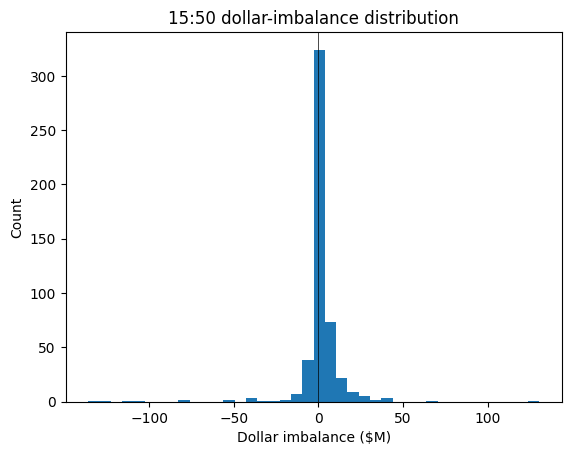

In [13]:
# TODO: `snap_big` should be a pd.DataFrame - a subset of `snap` with the
#       SAME columns, keeping only rows where the ABSOLUTE VALUE of the
#       'dollar_imbalance' column exceeds DOLLAR_IMBALANCE_THRESHOLD (= 500_000).
#       Pattern:
#           mask = snap['dollar_imbalance'].abs() > DOLLAR_IMBALANCE_THRESHOLD
#           snap_big = snap[mask]
snap_big: pd.DataFrame = snap[snap['dollar_imbalance'].abs() > DOLLAR_IMBALANCE_THRESHOLD]

print(f'{len(snap_big):,} names pass the $500k filter')

plt.hist(snap_big['dollar_imbalance'] / 1e6, bins=40)
plt.xlabel('Dollar imbalance ($M)'); plt.ylabel('Count')
plt.title('15:50 dollar-imbalance distribution'); plt.axvline(0, color='k', lw=0.5)
plt.show()


**Q2 Answer.** How many names pass the $500k filter?

Answer: `500`

---
## Question 3 — Return from the 15:50 reference price to the official close

For every filtered symbol, compute

$$r_i = \frac{\text{close\_px}_i}{\text{reference\_price}_i} - 1$$

The `ds` dataframe below already has `close_px` (from the MsgType 111 closing cross) and `reference_price` (from the 15:50 snapshot) joined. Add the `ret_to_close` column.

In [14]:
ds = snap_big.merge(daily, on='symbol', how='inner')
ds = ds[(ds['close_px'] > 0) & (ds['reference_price'] > 0) & (ds['total_vol'] > 0)].copy()

# TODO: Add a new column named 'ret_to_close' to the DataFrame `ds`.
#       It should be a float Series (one value per row) computed as:
#           close_px / reference_price - 1
#       Both `close_px` and `reference_price` are already columns in `ds`.
#       Pattern:
#           ds['ret_to_close'] = ds['close_px'] / ds['reference_price'] - 1
ds['ret_to_close'] = (ds["close_px"] / ds["reference_price"]) - 1

print(f'{len(ds):,} names with full data')
print(f'Mean return to close : {ds["ret_to_close"].mean():+.4%}')
print(f'Stdev                : {ds["ret_to_close"].std():.4%}')


500 names with full data
Mean return to close : +0.1823%
Stdev                : 0.2581%


**Q3 Answer.** Mean `ret_to_close` in basis points (1 bp = 0.01%).

Answer: `1823 bps`

In [15]:
ds

,symbol,date_x,partition,msg_type,seq_num,source_time,symbol_seq_num,reference_price,paired_qty,total_imbalance_qty,...,unpaired_side,significant_imbalance,signed_qty,dollar_imbalance,date_y,close_px,close_vol,close_time,total_vol,ret_to_close
0,ABM,20260102,1,105,11570930,15:50:00.577072917,24785,42.530,42324,13608,...,B,,13608.0,5.787482e+05,20260102,42.68,73619.0,16:00:02.744474210,535743,0.003527
1,ACI,20260102,2,105,11076122,15:50:00.444419642,100936,17.290,476068,76463,...,S,,-76463.0,-1.322045e+06,20260102,17.31,679796.0,16:00:02.313674232,4121648,0.001157
2,ACM,20260102,1,105,11571504,15:50:00.581190912,20744,96.200,178721,70374,...,B,,70374.0,6.769979e+06,20260102,96.40,259890.0,16:00:02.426723862,1042142,0.002079
3,ACN,20260102,5,105,11526524,15:50:00.584071971,108691,260.560,286780,430531,...,S,,-430531.0,-1.121792e+08,20260102,259.95,1159625.0,16:00:02.676854554,3530826,-0.002341
4,ACVA,20260102,3,105,10687565,15:50:00.722771462,40548,8.320,221486,82144,...,S,,-82144.0,-6.834381e+05,20260102,8.29,451615.0,16:00:02.371905604,2603924,-0.003606
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,YELP,20260102,4,105,10404957,15:50:00.490707962,32423,30.160,87568,27020,...,B,,27020.0,8.149232e+05,20260102,30.20,193233.0,16:00:02.502100853,1044918,0.001326
496,YETI,20260102,3,105,10687563,15:50:00.722764639,25129,44.720,100565,34052,...,B,,34052.0,1.522805e+06,20260102,44.84,182030.0,16:00:02.610412125,1208033,0.002683
497,YMM,20260102,5,105,11527138,15:50:00.587240150,77865,11.285,55846,128579,...,S,,-128579.0,-1.451014e+06,20260102,11.25,224398.0,16:00:02.370723974,4512519,-0.003101
498,ZBH,20260102,3,105,10686305,15:50:00.716003602,38390,90.050,71978,64927,...,B,,64927.0,5.846676e+06,20260102,90.02,179937.0,16:00:02.781565225,945954,-0.000333


---
## Question 4 — Signal construction and regression

### 4a. Normalize the signed imbalance by day volume

Build a signal $s_i$ that measures how big the imbalance is *relative to how much the stock normally trades in a day*. Divide the signed imbalance quantity by the stock's total NYSE day volume:

$$s_i = \frac{\text{signed\_qty}_i}{\text{total\_vol}_i}$$

$s_i$ is a small signed number: positive when the imbalance is to buy, negative when the imbalance is to sell.

In [16]:
# TODO: Add a new column named 'imbalance_frac' to `ds`.
#       Float Series (one value per row):
#           imbalance_frac = signed_qty / total_vol
#       Both `signed_qty` and `total_vol` are already columns in `ds`.
ds['imbalance_frac'] = ds["signed_qty"] / ds['total_vol']

ds[['symbol', 'signed_qty', 'total_vol', 'imbalance_frac']].head()


,symbol,signed_qty,total_vol,imbalance_frac
0,ABM,13608.0,535743,0.025400
1,ACI,-76463.0,4121648,-0.018552
2,ACM,70374.0,1042142,0.067528
3,ACN,-430531.0,3530826,-0.121935
4,ACVA,-82144.0,2603924,-0.031546


### 4b. Regress `ret_to_close` on `imbalance_frac`

Cross-sectional OLS with an intercept:

$$r_i = \alpha + \beta\, s_i + \varepsilon_i$$

Each observation $i$ is one NYSE symbol on 2026-01-02. The dependent variable $r_i$ is the return from the 15:50 reference price to the official close (Q3). The independent variable $s_i$ is the 15:50 signed imbalance normalized by day volume (Q4a).

* $\beta$ tells us how much the return moves with the signal. If positive, stocks with larger *buy* imbalances tend to clear at higher prices at the close.
* $R^2$ tells us what fraction of the cross-sectional variance in `ret_to_close` is explained by `imbalance_frac` on this day.

Use `sm.OLS(y, X).fit()` to fit the model. `X` already has the constant column added for you.

In [17]:
X = sm.add_constant(ds['imbalance_frac'])
y = ds['ret_to_close']

# TODO: `res` should be a statsmodels RegressionResultsWrapper - the fitted
#       OLS model. Syntax:
#           res = sm.OLS(y, X).fit()
#       The print calls below access:
#           res.params['const'], res.params['imbalance_frac']
#           res.rsquared
#           res.tvalues['imbalance_frac']
res = sm.OLS(y, X).fit()

print(f'alpha   = {res.params["const"]:+.5f}')
print(f'beta    = {res.params["imbalance_frac"]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta) = {res.tvalues["imbalance_frac"]:+.2f}')


alpha   = +0.00165
beta    = +0.01050
R^2     = 0.0425
t(beta) = +4.70


### 4c. Plot (just run)

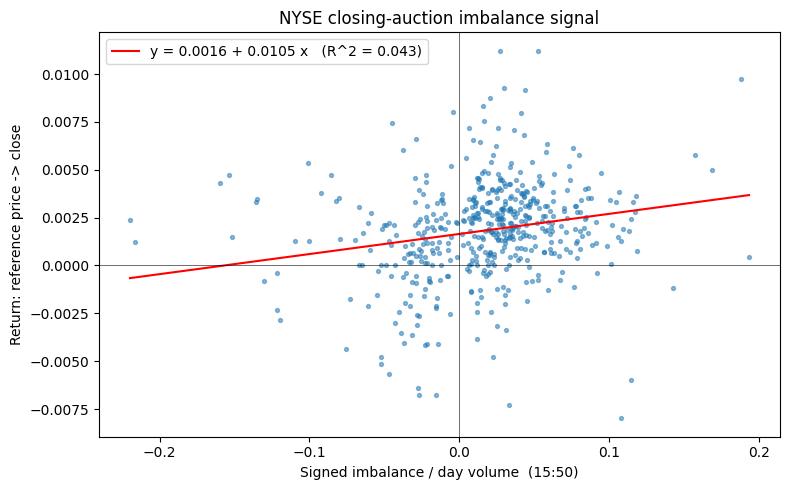

In [18]:
xs = np.linspace(ds['imbalance_frac'].min(), ds['imbalance_frac'].max(), 200)
ys = res.params['const'] + res.params['imbalance_frac'] * xs

plt.figure(figsize=(8, 5))
plt.scatter(ds['imbalance_frac'], ds['ret_to_close'], s=8, alpha=0.5)
plt.plot(xs, ys, color='red', lw=1.5,
         label=f"y = {res.params['const']:.4f} + {res.params['imbalance_frac']:.4f} x   (R^2 = {res.rsquared:.3f})")
plt.axhline(0, color='k', lw=0.4); plt.axvline(0, color='k', lw=0.4)
plt.xlabel('Signed imbalance / day volume  (15:50)')
plt.ylabel('Return: reference price -> close')
plt.title('NYSE closing-auction imbalance signal')
plt.legend(); plt.tight_layout(); plt.show()

**Q4 Answer.** Report $\hat{\beta}$ and $R^2$ to 4 decimals.

Answer: `beta = 0.0105    R^2 = 0.0425`

---
## Question 5 — Intraday strategy PL

The Q4 regression has a positive $\beta$: stocks with a *buy* imbalance at 15:50 tend to clear *above* their reference price at the close, and stocks with a *sell* imbalance clear *below*. Monetize this by trading in the direction of the published imbalance from 15:50 to 16:00.

**Strategy.** For each name in `ds`:

* **Entry side** `entry_side = sign(signed_qty)`: +1 (buy) when the imbalance is to buy, -1 (sell) when the imbalance is to sell.
* **Entry at 15:50**, at a fill price `fill_px = reference_price * (1 + entry_side * slip)` with $\text{slip} = 5\ \text{bp} = 0.0005$ — the reference price plus adverse slippage. We pay up when we buy, we receive less when we sell.
* **Size** each position at \$100,000 notional using the fill price. Shares are *signed*.
* **Exit** at the official close `close_px` (no slippage on the auction exit).

Per-name intraday PL:

$$\text{intra\_pl}_i = \text{shares}_i \cdot (\text{close\_px}_i - \text{fill\_px}_i)$$

In [19]:
ds.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 35 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   symbol                           500 non-null    object 
 1   date_x                           500 non-null    object 
 2   partition                        500 non-null    int64  
 3   msg_type                         500 non-null    object 
 4   seq_num                          500 non-null    object 
 5   source_time                      500 non-null    object 
 6   symbol_seq_num                   500 non-null    object 
 7   reference_price                  500 non-null    float64
 8   paired_qty                       500 non-null    int64  
 9   total_imbalance_qty              500 non-null    int64  
 10  market_imbalance_qty             500 non-null    int64  
 11  auction_time                     500 non-null    object 
 12  auction_type          

In [20]:
SLIP_BPS = 5
slip     = SLIP_BPS / 1e4   # 0.0005 = 5 basis points

# TODO: Add column 'entry_side' to `ds`.
#       int Series (one per row), values +1 or -1:
#           +1 when signed_qty > 0 (buy imbalance  - we BUY at 15:50)
#           -1 when signed_qty < 0 (sell imbalance - we SELL at 15:50)
#       Pattern:
#           np.sign(ds['signed_qty']).astype(int)
ds['entry_side'] = np.sign(ds['signed_qty']).astype(int)

# TODO: Add column 'fill_px' to `ds`.
#       float Series (one per row) - the 15:50 fill price with slippage:
#           fill_px = reference_price * (1 + entry_side * slip)
#       Reference_price is an existing column; entry_side was just set above;
#       `slip` is the float defined a few lines up.
ds['fill_px'] = ds['reference_price'] * (1 + ds['entry_side'] * slip)

# TODO: Add column 'intra_shares' to `ds`.
#       int Series (one per row), SIGNED (positive for longs, negative for shorts),
#       sized so that each name trades DOLLAR_PER_NAME (= 100_000) notional:
#           intra_shares = entry_side * round(DOLLAR_PER_NAME / fill_px)
#       The division gives a float Series; round with .round() then cast with
#       .astype(int) before multiplying by entry_side (int).
ds['intra_shares'] = ds['entry_side'] * round(DOLLAR_PER_NAME / ds['fill_px'])

# TODO: Add column 'intra_pl' to `ds`.
#       float Series (one per row), PL in dollars:
#           intra_pl = intra_shares * (close_px - fill_px)
ds['intra_pl'] = ds['intra_shares'] * (ds['close_px'] - ds['fill_px'])

ds['intra_notional'] = ds['intra_shares'].abs() * ds['fill_px']

ds[['symbol', 'signed_qty', 'entry_side', 'reference_price', 'fill_px',
    'close_px', 'intra_shares', 'intra_notional', 'intra_pl']].head()


,symbol,signed_qty,entry_side,reference_price,fill_px,close_px,intra_shares,intra_notional,intra_pl
0,ABM,13608.0,1,42.53,42.551265,42.68,2350.0,99995.472750,302.527250
1,ACI,-76463.0,-1,17.29,17.281355,17.31,-5787.0,100007.201385,-165.768615
2,ACM,70374.0,1,96.20,96.248100,96.40,1039.0,100001.775900,157.824100
3,ACN,-430531.0,-1,260.56,260.429720,259.95,-384.0,100005.012480,184.212480
4,ACVA,-82144.0,-1,8.32,8.315840,8.29,-12025.0,99997.976000,310.726000


### 5b. Portfolio summary (just run)

In [21]:
intra_summary = {
    'n_names'       : len(ds),
    'gross_notional': ds['intra_notional'].sum(),
    'net_pl'        : ds['intra_pl'].sum(),
    'mean_pl'       : ds['intra_pl'].mean(),
    'hit_rate'      : (ds['intra_pl'] > 0).mean(),
    'pl_per_dollar' : ds['intra_pl'].sum() / ds['intra_notional'].sum(),
}
for k, v in intra_summary.items():
    print(f'{k:<16} {v:>14,.4f}' if isinstance(v, float) else f'{k:<16} {v:>14}')

n_names                     500
gross_notional   49,898,636.4448
net_pl              45,742.3300
mean_pl                 91.4847
hit_rate                 0.6700
pl_per_dollar            0.0009


**Q5 Answer.** Net intraday PL (to the nearest dollar) and hit rate.

Answer: `net_pl = 45,742    hit_rate = 0.67`

---
## Question 6 — Overnight strategy PL (unhedged)

A different strategy from Q5. Here we step in at the *close* as a liquidity provider, taking the opposite side of the published imbalance, and we hold overnight.

* **Entry at the close**, at `close_px` (the official cross — the cross is our fill by construction).
* **Offset side** `offset_side = -sign(signed_qty)`: +1 (buy) when the imbalance is to *sell*, -1 (sell) when the imbalance is to *buy*.
* **Size** each position at \$100,000 notional using the close price.
* **Exit** at the 09:45 NBBO midpoint on 2026-01-05.

### 6a. Pull next-morning NBBO mids from WRDS

In [22]:
import wrds
conn = wrds.Connection(wrds_username='nelkshake')   # <-- change if different

clean_symbols = [s for s in ds['symbol'].tolist() if s.isalpha()]
syms_sql = ",".join(f"'{s}'" for s in clean_symbols)

q = f"""
  SELECT DISTINCT ON (sym_root) sym_root AS symbol,
         (best_bid + best_ask) / 2.0 AS exit_px
  FROM   taqm_2026.nbbom_{NEXT_DATE}
  WHERE  sym_root IN ({syms_sql})
    AND  (sym_suffix IS NULL OR sym_suffix = '')
    AND  best_bid > 0 AND best_ask > best_bid
    AND  time_m >= TIME '09:45:00'
  ORDER BY sym_root, time_m, time_m_nano
"""
exits = conn.raw_sql(q)
print(f'Fetched 09:45 mids for {len(exits):,} symbols on {NEXT_DATE}')
exits.head()

Loading library list...
Done
Fetched 09:45 mids for 496 symbols on 20260105


,symbol,exit_px
0,ABM,42.9
1,ACI,17.165
2,ACM,97.995
3,ACN,262.795
4,ACVA,8.195


### 6b. Compute per-symbol overnight PL

In [35]:
pl = ds.merge(exits, on='symbol', how='inner')

# TODO: Add column 'offset_side' to `pl`.
#       int Series (one per row), values +1 or -1 - the OPPOSITE sign of the
#       imbalance direction (we are liquidity providers):
#           +1 (we BUY at close) when signed_qty < 0 (sell imbalance)
#           -1 (we SELL at close) when signed_qty > 0 (buy imbalance)
#       Pattern:
#           -np.sign(pl['signed_qty']).astype(int)
pl['offset_side'] = -np.sign(pl['signed_qty']).astype(int)

# TODO: Add column 'shares' to `pl`.
#       int Series, signed, sized to DOLLAR_PER_NAME notional at the close price:
#           shares = offset_side * round(DOLLAR_PER_NAME / close_px)
#       Same shape as Q5's intra_shares, but using offset_side and close_px.
pl['shares'] = pl['offset_side'] * round(DOLLAR_PER_NAME / pl['close_px'])

# TODO: Add column 'pl' to `pl` (the DataFrame - yes, same name as column).
#       float Series, overnight PL per name in dollars:
#           pl = shares * (exit_px - close_px)
#       exit_px comes from the WRDS query in Q6a (09:45 NBBO mid next morning).
pl['pl'] = pl["shares"] * (pl["exit_px"] - pl["close_px"])

pl['notional']      = pl['shares'].abs() * pl['close_px']
pl['overnight_ret'] = pl['exit_px'] / pl['close_px'] - 1

pl[['symbol', 'signed_qty', 'offset_side', 'close_px', 'exit_px',
    'shares', 'notional', 'pl', 'overnight_ret']].head()


,symbol,signed_qty,offset_side,close_px,exit_px,shares,notional,pl,overnight_ret
0,ABM,13608.0,-1,42.68,42.9,-2343.0,99999.24,-515.46,0.005155
1,ACI,-76463.0,1,17.31,17.165,5777.0,99999.87,-837.665,-0.008377
2,ACM,70374.0,-1,96.40,97.995,-1037.0,99966.80,-1654.015,0.016546
3,ACN,-430531.0,1,259.95,262.795,385.0,100080.75,1095.325,0.010944
4,ACVA,-82144.0,1,8.29,8.195,12063.0,100002.27,-1145.985,-0.01146


### 6c. Portfolio summary (just run)

In [36]:
overnight_summary = {
    'n_names'       : len(pl),
    'gross_notional': pl['notional'].sum(),
    'net_pl'        : pl['pl'].sum(),
    'mean_pl'       : pl['pl'].mean(),
    'hit_rate'      : (pl['pl'] > 0).mean(),
    'pl_per_dollar' : pl['pl'].sum() / pl['notional'].sum(),
}
for k, v in overnight_summary.items():
    print(f'{k:<16} {v:>14,.4f}' if isinstance(v, float) else f'{k:<16} {v:>14}')

pl.to_csv('overnight_pl.csv', index=False)
print('\nwrote overnight_pl.csv')

n_names                     496
gross_notional   49,597,226.4300
net_pl            -155,076.9800
mean_pl               -312.6552
hit_rate                 0.4415
pl_per_dollar           -0.0031

wrote overnight_pl.csv


**Q6 Answer.** Net overnight PL (to the nearest dollar) and hit rate.

Answer: `net_pl = -155,076.9800    hit_rate = 0.4415`

---
## Question 7 — SPY-hedged overnight strategy

The unhedged Q6 book has market-beta exposure equal to its *net* notional. If more names have buy imbalances than sell imbalances (or vice versa), the book is net short (or long) the market, and overnight market drift can swamp the cross-sectional imbalance signal.

Fix: hedge with SPY. Take a SPY position of size $-\text{net\_notional}$ at the Arca Official Closing Price on 2026-01-02, exit at the 09:45 NBBO midpoint on 2026-01-05. Assume beta = 1 for every name.

### 7a. Compute net notional

$$\text{net\_notional} = \sum_i \text{offset\_side}_i \cdot \text{notional}_i$$

In [37]:
# TODO: `net_notional` should be a single float - the signed dollar exposure
#       of the overnight book, summed across all names:
#           net_notional = sum over rows of (offset_side * notional)
#       Both are columns in the `pl` DataFrame from Q6b.
#       Pattern:
#           (pl['offset_side'] * pl['notional']).sum()
#       Positive value => book is net LONG the market.
#       Negative value => book is net SHORT the market.
net_notional: float = (pl['offset_side'] * pl['notional']).sum()

n_long  = (pl['offset_side'] ==  1).sum()
n_short = (pl['offset_side'] == -1).sum()
print(f'Long leg  : {n_long:>4} names, ${pl.loc[pl.offset_side== 1,"notional"].sum():>14,.0f}')
print(f'Short leg : {n_short:>4} names, ${pl.loc[pl.offset_side==-1,"notional"].sum():>14,.0f}')
print(f'NET       : {"long" if net_notional > 0 else "short":>4}       ${net_notional:>+14,.0f}')


Long leg  :  150 names, $    15,000,118
Short leg :  346 names, $    34,597,109
NET       : short       $   -19,596,991


### 7b. Pull SPY official close + 09:45 mid from WRDS (just run)

In [38]:
spy_close_px = conn.raw_sql(f"""
  SELECT price
  FROM   taqm_2026.ctm_{TARGET_DATE}
  WHERE  sym_root = 'SPY' AND (sym_suffix IS NULL OR sym_suffix = '')
    AND  ex = 'P'
    AND  time_m BETWEEN TIME '15:59:50' AND TIME '16:01:00'
    AND  POSITION('M' IN tr_scond) > 0
    AND  price > 0
  ORDER BY time_m, time_m_nano
  LIMIT 1
""").iloc[0, 0]

spy_exit_px = conn.raw_sql(f"""
  SELECT (best_bid + best_ask) / 2.0 AS mid
  FROM   taqm_2026.nbbom_{NEXT_DATE}
  WHERE  sym_root = 'SPY' AND (sym_suffix IS NULL OR sym_suffix = '')
    AND  time_m >= TIME '09:45:00'
    AND  best_bid > 0 AND best_ask > best_bid
  ORDER BY time_m, time_m_nano
  LIMIT 1
""").iloc[0, 0]

spy_close_px = float(spy_close_px); spy_exit_px = float(spy_exit_px)
spy_ret = spy_exit_px / spy_close_px - 1
print(f'SPY 2026-01-02 Official Close : ${spy_close_px:.4f}')
print(f'SPY 2026-01-05 09:45 mid      : ${spy_exit_px:.4f}')
print(f'SPY overnight return          : {spy_ret:+.4%}')

SPY 2026-01-02 Official Close : $683.1700
SPY 2026-01-05 09:45 mid      : $687.4050
SPY overnight return          : +0.6199%


### 7c. Compute the SPY hedge leg

Hedge shares are the opposite sign of `net_notional`, divided by the SPY close, rounded to an integer.

In [39]:
# TODO: `spy_shares` should be a single signed int (positive = long SPY, negative
#       = short SPY). The hedge flips the sign of the book's net notional:
#           spy_shares = -round(net_notional / spy_close_px)
#       spy_close_px is a float set in Q7b. Use int(round(...)) to get a plain int.
spy_shares: int = -round(net_notional / spy_close_px)

# TODO: `spy_pl` should be a single float - PL on the SPY leg, in dollars:
#           spy_pl = spy_shares * (spy_exit_px - spy_close_px)
#       Both SPY prices are scalars set in Q7b.
spy_pl: float = spy_shares * (spy_exit_px - spy_close_px)

# TODO: `hedged_pl` should be a single float - total PL of the HEDGED overnight
#       book (stock names + SPY leg):
#           hedged_pl = pl['pl'].sum() + spy_pl
hedged_pl: float = pl['pl'].sum() + spy_pl

print(f'SPY hedge shares    : {spy_shares:>+10,d}')
print(f'SPY hedge notional  : ${abs(spy_shares) * spy_close_px:>14,.0f}')
print(f'SPY leg PL          : ${spy_pl:>+14,.2f}')
print(f'Stock-book PL       : ${pl["pl"].sum():>+14,.2f}')
print(f'HEDGED total PL     : ${hedged_pl:>+14,.2f}')


SPY hedge shares    :    +28,685
SPY hedge notional  : $    19,596,731
SPY leg PL          : $   +121,480.98
Stock-book PL       : $   -155,076.98
HEDGED total PL     : $    -33,596.00


### 7d. Side-by-side strategy comparison (just run)

In [40]:
rows = [
    ('Intraday ride-with, 15:50 -> close        (Q5)',
        len(ds), ds['intra_notional'].sum(), ds['intra_pl'].sum()),
    ('Overnight offset unhedged, close -> 09:45 (Q6)',
        len(pl), pl['notional'].sum(),       pl['pl'].sum()),
    ('Overnight offset + SPY hedge              (Q7)',
        len(pl), pl['notional'].sum() + abs(spy_shares)*spy_close_px, hedged_pl),
]
print(f'{"strategy":<52} {"n":>5} {"gross $":>16} {"PL $":>14} {"bp":>8}')
for name, n, nl, p in rows:
    bp = 1e4 * p / nl if nl else 0
    print(f'{name:<52} {n:>5} {nl:>16,.0f} {p:>+14,.2f} {bp:>+8.2f}')

strategy                                                 n          gross $           PL $       bp
Intraday ride-with, 15:50 -> close        (Q5)         500       49,898,636     +45,742.33    +9.17
Overnight offset unhedged, close -> 09:45 (Q6)         496       49,597,226    -155,076.98   -31.27
Overnight offset + SPY hedge              (Q7)         496       69,193,958     -33,596.00    -4.86


**Q7 Answer.** Hedged total PL and SPY leg PL (both to the nearest dollar).

Answer: `hedged_pl = -33,596.00   spy_pl = +121,480.98`

---
## Done

Submit with all cells executed and the seven `Answer:` lines filled in.